In [1]:
import numpy as np
import os
import soundfile as sf 
import librosa
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns


In [2]:
# Function that finds all files with a certain extension in a particular folder
def find_all_files(folders, ext, check_sub_folders=1):
    """Find all files with a .txt extension in all folders in folder list (and subfolders if check_sub_folders = 1 (default))"""
    all_files = []
    if isinstance(folders, str):
        # Make sure input is a list of folders
        folders = [folders]
    for f, folder in enumerate(folders):
        for subfolder in os.listdir(folder):

            if os.path.isdir(os.path.join(folder, subfolder)):
                if check_sub_folders:
                    folders.append(os.path.join(folder, subfolder))                
            elif subfolder.endswith(ext):
                all_files.append(os.path.join(folder,subfolder))
    return all_files

In [3]:
# Function that pads or cuts a spectrogram to a certain size, adapted from avgn
def pad_spectrogram(spectrogram, pad_length):
    """ Pads a spectrogram to being a certain length
    """
    excess_needed = pad_length - np.shape(spectrogram)[1]
    pad_left = np.floor(float(excess_needed) / 2).astype("int")
    pad_right = np.ceil(float(excess_needed) / 2).astype("int")
    if excess_needed >= 0:
        return np.pad(
            spectrogram, [(0, 0), (pad_left, pad_right)], "constant", constant_values=0
        )
    else:
        pad_left = np.floor(float(excess_needed) / 2).astype("int")
        pad_right = np.ceil(float(excess_needed) / 2).astype("int")
        return spectrogram[:,-1*pad_left:pad_right]

## Setup

In [4]:
# Constant variables
fmin = 1000
fmax = 20000 # Max frequency cutoff
spec_shape = [128, 128] #Shape of spectrogram
n_fft = 2048
hop_length = int(n_fft/2)


In [5]:
# Find all the audio files
data_folder = r"test_data"
data_files = find_all_files(data_folder, '.flac')

For these methods, we ideally want all spectrograms to have the same dimensions (spec_shape). We will thus pad the spectrograms to add margins to the side.

In [6]:
## Example data file
file = data_files[500]
data, sr = sf.read(file) # read in the file using soundfile

# Calculate spectrograms
mel_spec = librosa.feature.melspectrogram(y=data, sr=sr, n_mels=128, n_fft=n_fft, hop_length = hop_length)
padded_spec = pad_spectrogram(mel_spec, spec_shape[1])
print(padded_spec.shape)

(128, 128)


Text(0.5, 1.0, 'Padded')

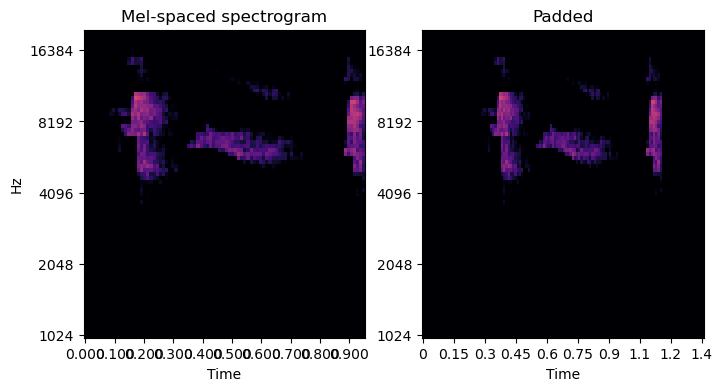

In [7]:
fig, ax = plt.subplots(ncols=2, sharex=False, figsize=(8, 4))
mel_img = librosa.display.specshow(mel_spec, x_axis='time', y_axis='mel',vscale="dBFS",sr=sr, ax=ax[0],  n_fft=n_fft, hop_length = hop_length)
ax[0].set_ylim((fmin, fmax))
ax[0].set_title('Mel-spaced spectrogram')

padded_img = librosa.display.specshow(padded_spec, x_axis='time', y_axis='mel',vscale="dBFS",sr=sr, ax=ax[1],  n_fft=n_fft, hop_length = hop_length)
ax[1].set_ylim((fmin, fmax))
ax[1].set_title('Padded')

# Preprocessing the data

We want to run through all the calls and extract spectrograms. In this case, the code below does, and saves it into a TF records format, which is a binary format (for more info see [here](https://www.tensorflow.org/tutorials/load_data/tfrecord). This is largely for practicality, as it prevents you from having to hold all the calls in the memory at the same time and speeds up computation, especially if you have access to a GPU. The methods here were developed by Tim Sainburg and adapted from his [AVGN](https://github.com/timsainb/AVGN) package.

In [12]:
from avgn_utils import spec_to_record
import tensorflow as tf
n_records = 0
record_loc = r"marmoset_calls.tfrecords"
# Run through each audio file and extract the spectrograms
with tf.io.TFRecordWriter(record_loc) as writer:
    for i, file in enumerate(data_files):
        data, sr = sf.read(file) 
        call_type = os.path.basename(file).split('_')[0]
        call_id = os.path.splitext(os.path.basename(file))[0].split('_')[1]
        
        duration = len(data)/sr
    
        mel_spec = librosa.feature.melspectrogram(y=data, sr=sr, n_mels=128, n_fft=n_fft, hop_length = hop_length)
        padded_spec = pad_spectrogram(mel_spec, spec_shape[1])
    
        record = spec_to_record(padded_spec, call_id, call_type) 
        writer.write(record)
        n_records +=1
    print(n_records)

2020


b'\n\xcd\x80\x08\n\x99\x80\x08\n\x0bspectrogram\x12\x88\x80\x08\n\x84\x80\x08\n\x80\x80\x08l\xb0u\xfa\xd0\xdb\x19@d\x1dux\xf9k\x00@\xd6\xac\x12\x8e\x00\x0f*@\x08\x91n0\x18\n\xd5?>#\xc2|\xf3c5@/=Kj,%\xfe?]\x1e\x8a\xf6>\x822@AA\xd9oT\x8d\x05@yX\xe6\xb49\xb1!@\xac{\xd8\xc4\nu\x12@\xb9\xb0\'\xd2:\x8c\x1d@[d\xea~\x04\xe6\r@\xb6X\xac+\xa4\xaa @40Q\'\xe4\xae\x12@\xb51\x8b1\xdc\x13\x16@+xwL\xf8 \x13@\xc3#\xe1\x80\xde\xc5\x18@\x11!\xe1\xa8\x1dM\x01@\xaacXD\x92y(@g\xa3\xc2\x11\xdd\xbb\xeb?\xd4\xb3\xe3\xe9t\xbb$@\x14\x80\x03\xee\xf2\x07\x08@\xa6\xe2e#l\xf2\x15@\x847\xc2\x80\xb8\x84\x1d@\xa1\x14q\x11\xf2\xed\x10@\xbd\xe0\xd7\xc7/\xac\x1b@\xe8S\x81a\xd3o\x0c@f\x80\xcf\x0e\x15n&@\x19EY3\xb6D\x08@/\tZ\nch1@\xcepkD\x1f\x05\xf9?\xe8A\xd4-\xfd\x8c2@\xb6\x96\xff\xafN\xef\xf7?\x02\xa0\xb2L\xea/\x1c@\x9b*\x19$\x99\x8d\x1e@Z\xde\xcf\xdc\xc1a\x01@\x03$\xb6\xa9e\xb50@<Um\x8c\xbe\xb9\x13@\xb8P\x1e\xc5($.@\x85\x99\x9exf\xaf\t@^\x12\xd3\n j\x1b@O\xa6bf\x1a\xf0\x15@\x05\x86\xf8\xecM\x04\x1c@`\x9e\xe7\x05\xc1~\x04